In [192]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns

In [193]:
df=pd.read_csv("world_bank_country_data.csv")

In [194]:
df.head()

,country,indicator,date,value
0,Belgium,Total electricity output (GWh),2015,69548.0
1,Belgium,Total electricity output (GWh),2014,71455.0
2,Belgium,Total electricity output (GWh),2013,82183.0
3,Belgium,Total electricity output (GWh),2012,81621.0
4,Belgium,Total electricity output (GWh),2011,89014.0


In [195]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12101 entries, 0 to 12100
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    12101 non-null  object 
 1   indicator  12101 non-null  object 
 2   date       12101 non-null  int64  
 3   value      12101 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 378.3+ KB


In [196]:
df.describe()

,date,value
count,12101.000000,1.210100e+04
mean,1996.776465,2.260610e+11
std,17.098940,1.186497e+12
min,1960.000000,-9.711190e+11
25%,1983.000000,1.021779e+01
50%,1999.000000,5.563800e+01
75%,2011.000000,2.524318e+10
max,2024.000000,2.736094e+13


In [197]:
df.isna().sum()

country      0
indicator    0
date         0
value        0
dtype: int64

In [198]:
#Filtramos a nuestro pais
df= df[df["country"] == "Netherlands"]
df
#Vemos que hay unos cuantos outliers

,country,indicator,date,value
156,Netherlands,Total electricity output (GWh),2015,110070.000000
157,Netherlands,Total electricity output (GWh),2014,103418.000000
158,Netherlands,Total electricity output (GWh),2013,101736.000000
159,Netherlands,Total electricity output (GWh),2012,103298.000000
160,Netherlands,Total electricity output (GWh),2011,113963.000000
...,...,...,...,...
12080,Netherlands,High-technology exports (% of manufactured exp...,2011,25.207728
12081,Netherlands,High-technology exports (% of manufactured exp...,2010,27.825528
12082,Netherlands,High-technology exports (% of manufactured exp...,2009,28.000410
12083,Netherlands,High-technology exports (% of manufactured exp...,2008,26.012620


In [199]:
#Detectamos outliers conel modelo del iqr dado en gestion
q1 = df['value'].quantile(0.25)
q3 = df['value'].quantile(0.75)
iqr = q3 - q1
print(iqr)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

30005429174.637276


In [200]:
outliers_iqr = (df['value'] < limite_inferior)|(df['value'] > limite_superior)
df[outliers_iqr]

,country,indicator,date,value
2170,Netherlands,General government final consumption expenditu...,2023,2.828545e+11
2171,Netherlands,General government final consumption expenditu...,2022,2.532582e+11
2172,Netherlands,General government final consumption expenditu...,2021,2.652165e+11
2173,Netherlands,General government final consumption expenditu...,2020,2.370502e+11
2174,Netherlands,General government final consumption expenditu...,2019,2.240449e+11
...,...,...,...,...
11951,Netherlands,High-technology exports (current US$),2012,8.143030e+10
11952,Netherlands,High-technology exports (current US$),2011,8.591761e+10
11953,Netherlands,High-technology exports (current US$),2010,7.748543e+10
11955,Netherlands,High-technology exports (current US$),2008,7.831371e+10


In [201]:
outliers_iqr.sum()
#De 1600 filas hay 300 que son outliers, que es bastante, pero al ser datos economicos no vamos a imputarlos porque es algo normal

np.int64(306)

In [202]:
df_filtrado = df
df_filtrado

,country,indicator,date,value
156,Netherlands,Total electricity output (GWh),2015,110070.000000
157,Netherlands,Total electricity output (GWh),2014,103418.000000
158,Netherlands,Total electricity output (GWh),2013,101736.000000
159,Netherlands,Total electricity output (GWh),2012,103298.000000
160,Netherlands,Total electricity output (GWh),2011,113963.000000
...,...,...,...,...
12080,Netherlands,High-technology exports (% of manufactured exp...,2011,25.207728
12081,Netherlands,High-technology exports (% of manufactured exp...,2010,27.825528
12082,Netherlands,High-technology exports (% of manufactured exp...,2009,28.000410
12083,Netherlands,High-technology exports (% of manufactured exp...,2008,26.012620


In [203]:
puerto = pd.read_csv("datosPuerto.csv", decimal=",")
#cargamos y iltramos el archivo del puerto. Pasamos la fecha a datetime y extraemos el año para agrupar los kilos por año
puerto['FECHA'] = pd.to_datetime(puerto['FECHA'])
puerto['FECHA'] = puerto['FECHA'].dt.year
#Filtramos las exportaciones y importaciones
exportaciones = puerto[(puerto["PAIS_FINAL"] == "NL") & (puerto["PAIS_ORIGEN"] == "ES")]
importaciones = puerto[(puerto["PAIS_FINAL"] == "ES") & (puerto["PAIS_ORIGEN"] == "NL")]
#Agrupamos los kilos por años
exportaciones = exportaciones.groupby("FECHA")["PESO_KILOS"].sum()
importaciones = importaciones.groupby("FECHA")["PESO_KILOS"].sum()

print("Importaciones", importaciones)

Importaciones FECHA
2007     960217716
2008     818883186
2009     826407028
2010    1096816180
2011     786733730
2012     925922346
2013     732426144
2014     785162500
2015     790342418
2016     690588712
2017     683978612
2018     696356457
2019     831587812
2020     520076382
2021     655221933
2022     254646377
2023     323879014
2024     376930596
Name: PESO_KILOS, dtype: int64


In [204]:
exportaciones = {
2009: 366543925,
2010: 410957443,
2011: 754842617,
2012: 540914746,
2013: 851701657,
2014: 940298629,
2015: 595610110,
2016: 844578531,
2017: 951613421,
2018: 971474553,
2019: 1154433286,
2020: 825988465,
2021: 1040936381,
2022: 661942327,
2023: 483180404,
2024: 741719313}


In [205]:
importaciones = {  
2009: 826407028,  
2010: 1096816180,  
2011: 786733730,  
2012: 925922346,  
2013: 732426144,  
2014: 785162500,  
2015: 790342418,  
2016: 690588712,  
2017: 683978612,  
2018: 696356457,  
2019: 831587812,  
2020: 520076382,  
2021: 655221933,  
2022: 254646377,  
2023: 323879014,  
2024: 376930596}

In [206]:
#Hacemos una serie con los kilos para que sea mas facil meterlo en el merge.
df_kilos_exportaciones = pd.Series(exportaciones).reset_index()
df_kilos_exportaciones.columns = ["date", "kilos"]
#hacemos un pivot_table y un merge para que se junten los datos de los kilos y los indicadores
df_pivot_exportaciones = df_filtrado.pivot_table(
    index="date",
    columns="indicator",
    values="value").reset_index()
df_merge_exportaciones = df_kilos_exportaciones.merge(df_pivot_exportaciones, on="date", how="left")
#Hacemos la correlacion de los indicadores para ver cuales tienen mas importancia
corr_exportaciones = df_merge_exportaciones.corr(numeric_only=True)
corr_exportaciones["kilos"].sort_values(ascending=False)

kilos                                                                                         1.000000
Export value index (2015 = 100)                                                               0.764190
Import value index (2015 = 100)                                                               0.732821
Services, value added (% of GDP)                                                              0.670598
Net food imports by crop - Barley                                                             0.649568
Machinery and transport equipment (% of value added in manufacturing)                         0.603462
High-technology exports (current US$)                                                         0.548666
Transport services (% of service exports, BoP)                                                0.536279
Food imports (% of merchandise imports)                                                       0.521546
Exports of goods and services (% of GDP)                                 

In [207]:
#Filttramos solo los indicadores mas correlacion tienen(poitiva y negativa para que el heatmap sea visible)
indicadores_elegidos = ["Export value index (2015 = 100)", "Import value index (2015 = 100)", "High-technology exports (% of manufactured exports)", "Total electricity output (GWh)", "Net food imports by crop - Barley", "Machinery and transport equipment (% of value added in manufacturing)", "High-technology exports (current US$)", "Food imports (% of merchandise imports)","kilos" ]
corr_exportaciones = corr_exportaciones.loc[indicadores_elegidos, indicadores_elegidos]

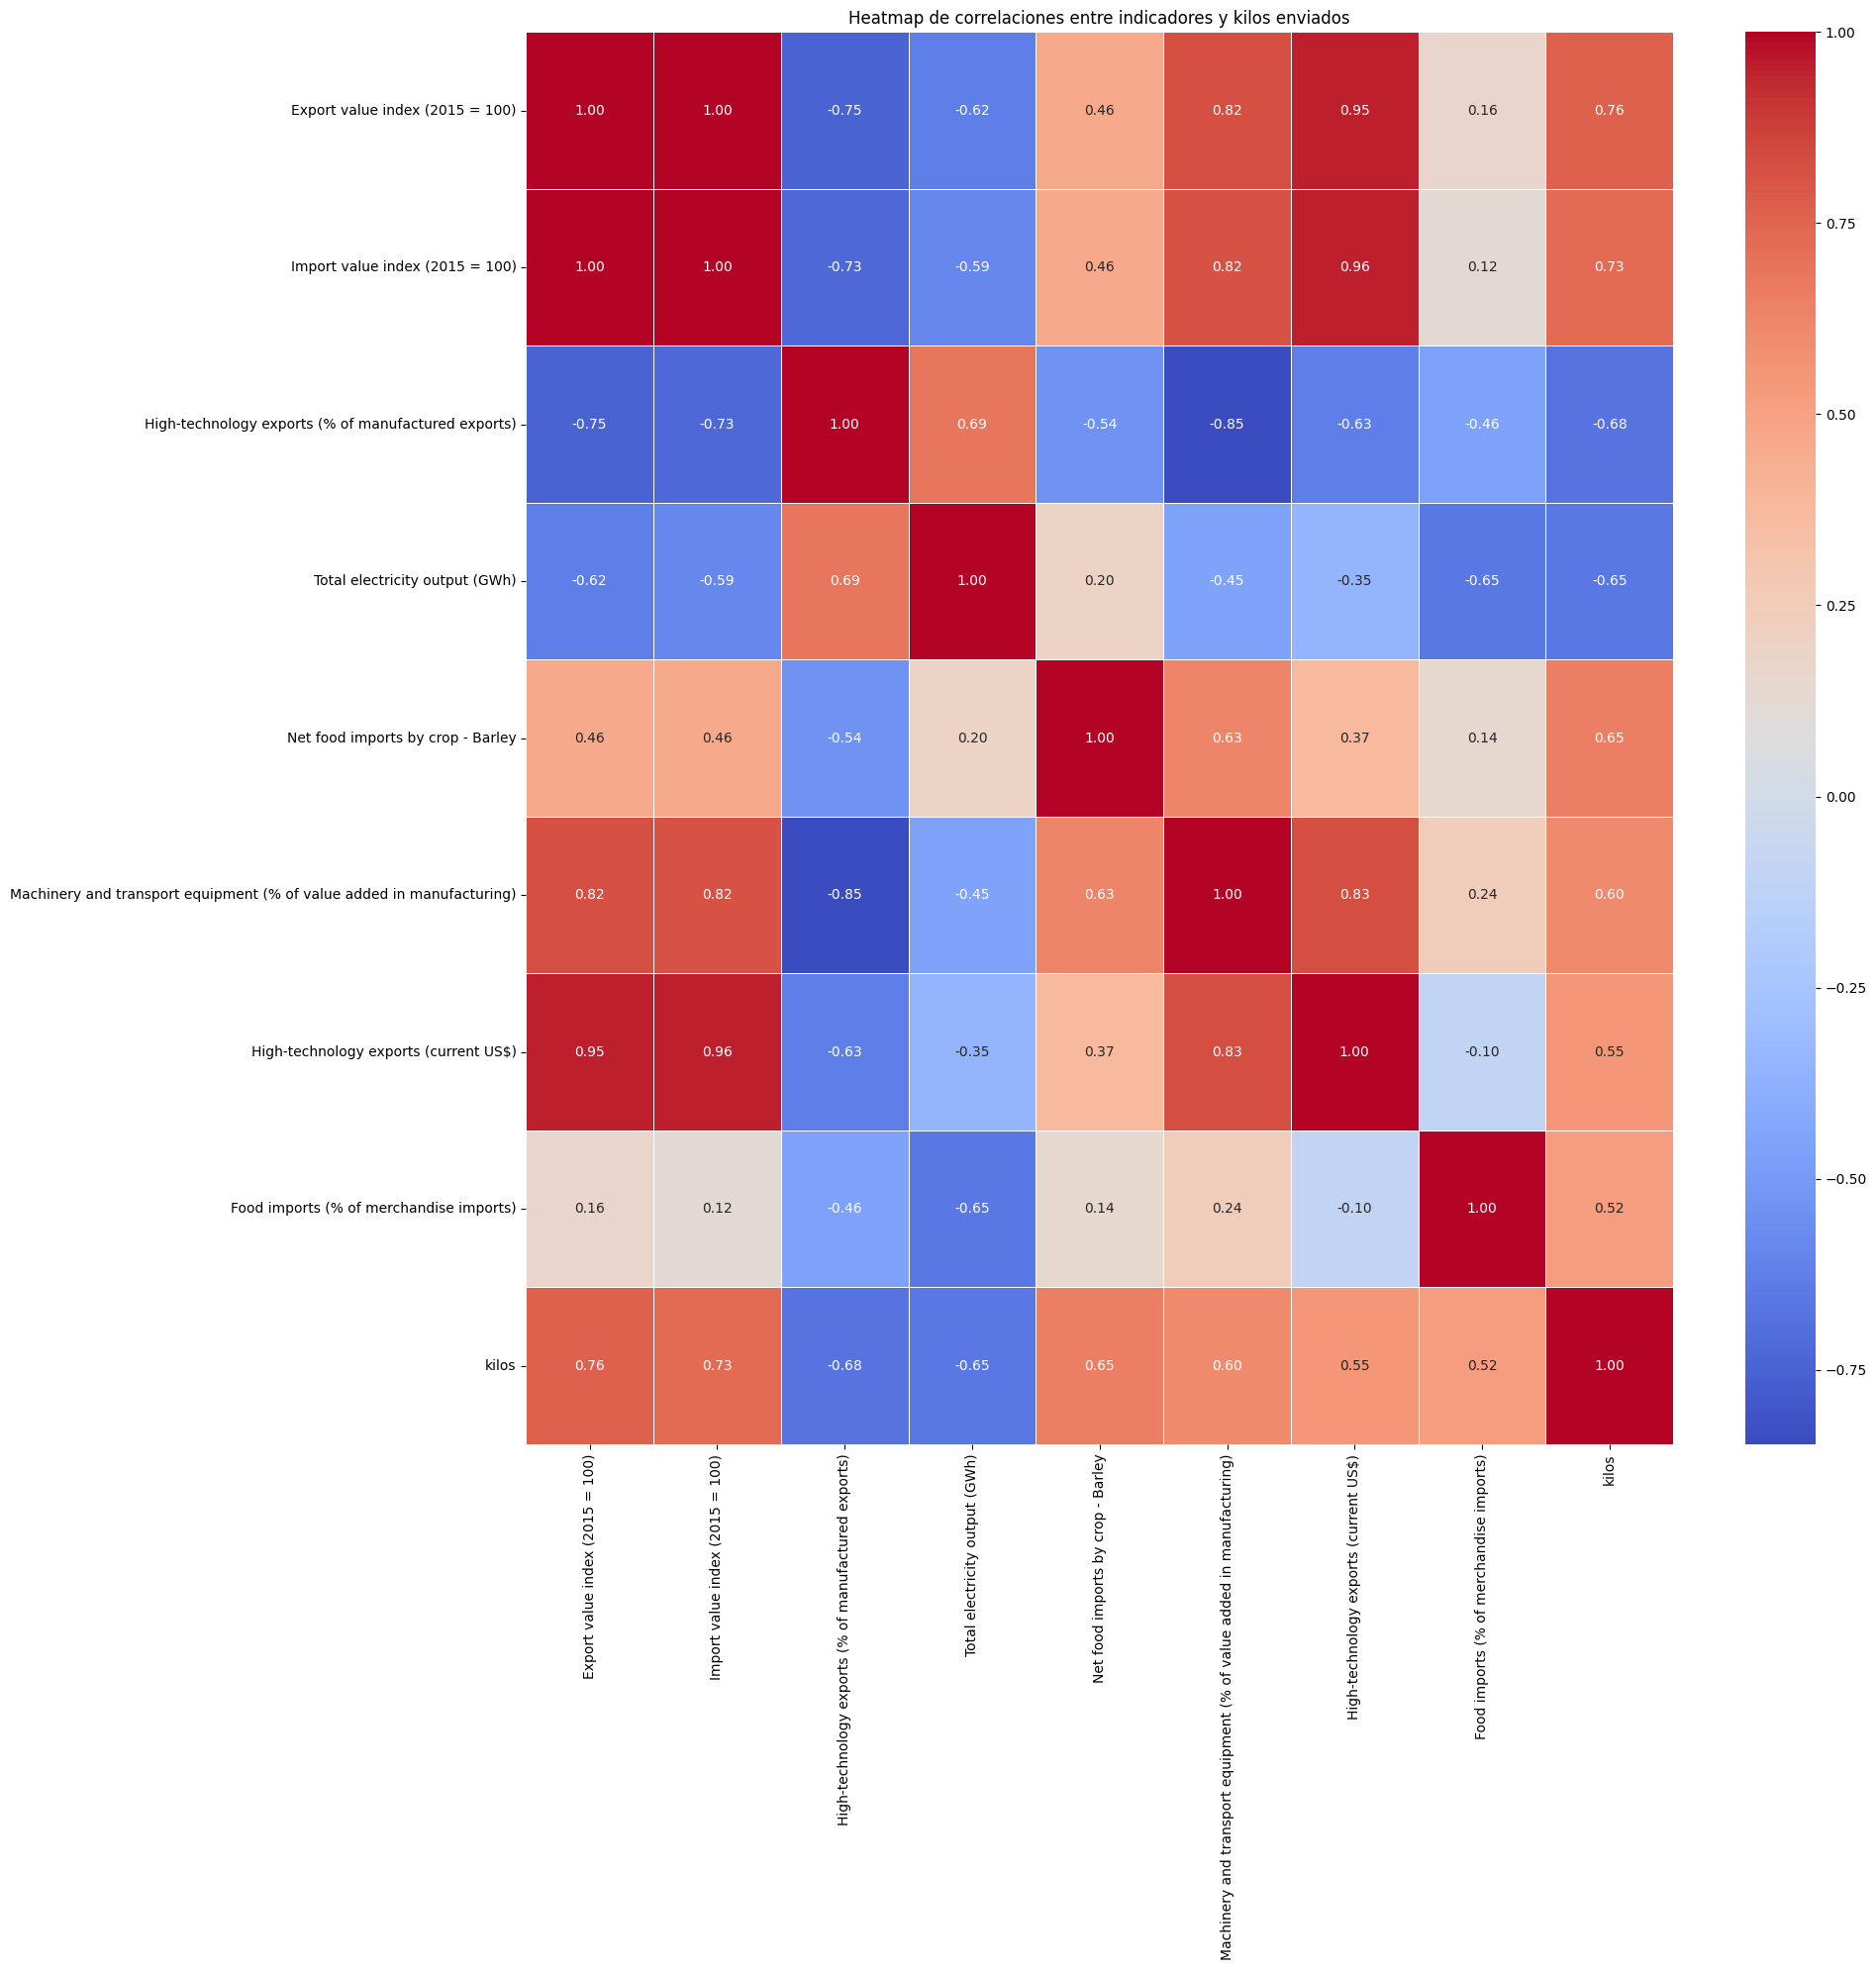

In [208]:
#Hacemos el heatmap
plt.figure(figsize=(20, 20))
sns.heatmap(
    corr_exportaciones,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Heatmap de correlaciones entre indicadores y kilos enviados")
plt.tight_layout()
plt.show()

In [209]:
#Hacemos una serie con los kilos para que sea mas facil meterlo en el merge.
df_kilos_importaciones = pd.Series(importaciones).reset_index()
df_kilos_importaciones.columns = ["date", "kilos"]
#hacemos un pivot_table y un merge para que se junten los datos de los kilos y los indicadores
df_pivot_importaciones = df_filtrado.pivot_table(
    index="date",
    columns="indicator",
    values="value").reset_index()
df_merge_importaciones = df_kilos_importaciones.merge(df_pivot_importaciones, on="date", how="left")
#Hacemos la correlacion de los indicadores para ver cuales tienen mas importancia
corr_importaciones = df_merge_importaciones.corr(numeric_only=True)
corr_importaciones["kilos"].sort_values(ascending=False)

kilos                                                                                         1.000000
High-technology exports (% of manufactured exports)                                           0.798041
ICT goods exports (% of total goods exports)                                                  0.779068
Total electricity output (GWh)                                                                0.566827
Insurance and financial services (% of service exports, BoP)                                  0.408119
Agricultural raw materials exports (% of merchandise exports)                                 0.333345
Transport services (% of service exports, BoP)                                                0.082212
Nominal Effecive Exchange Rate                                                               -0.094850
Fuel exports (% of merchandise exports)                                                      -0.158613
Services, value added (% of GDP)                                         

In [210]:
#Filttramos solo los indicadores mas correlacion tienen(poitiva y negativa para que el heatmap sea visible)
indicadores_elegidos = [ "Export value index (2015 = 100)", "Import value index (2015 = 100)", "High-technology exports (% of manufactured exports)", "Total electricity output (GWh)", "Net food imports by crop - Barley", "Machinery and transport equipment (% of value added in manufacturing)", "High-technology exports (current US$)", "Food imports (% of merchandise imports)","kilos" ]
corr_importaciones = corr_importaciones.loc[indicadores_elegidos, indicadores_elegidos]

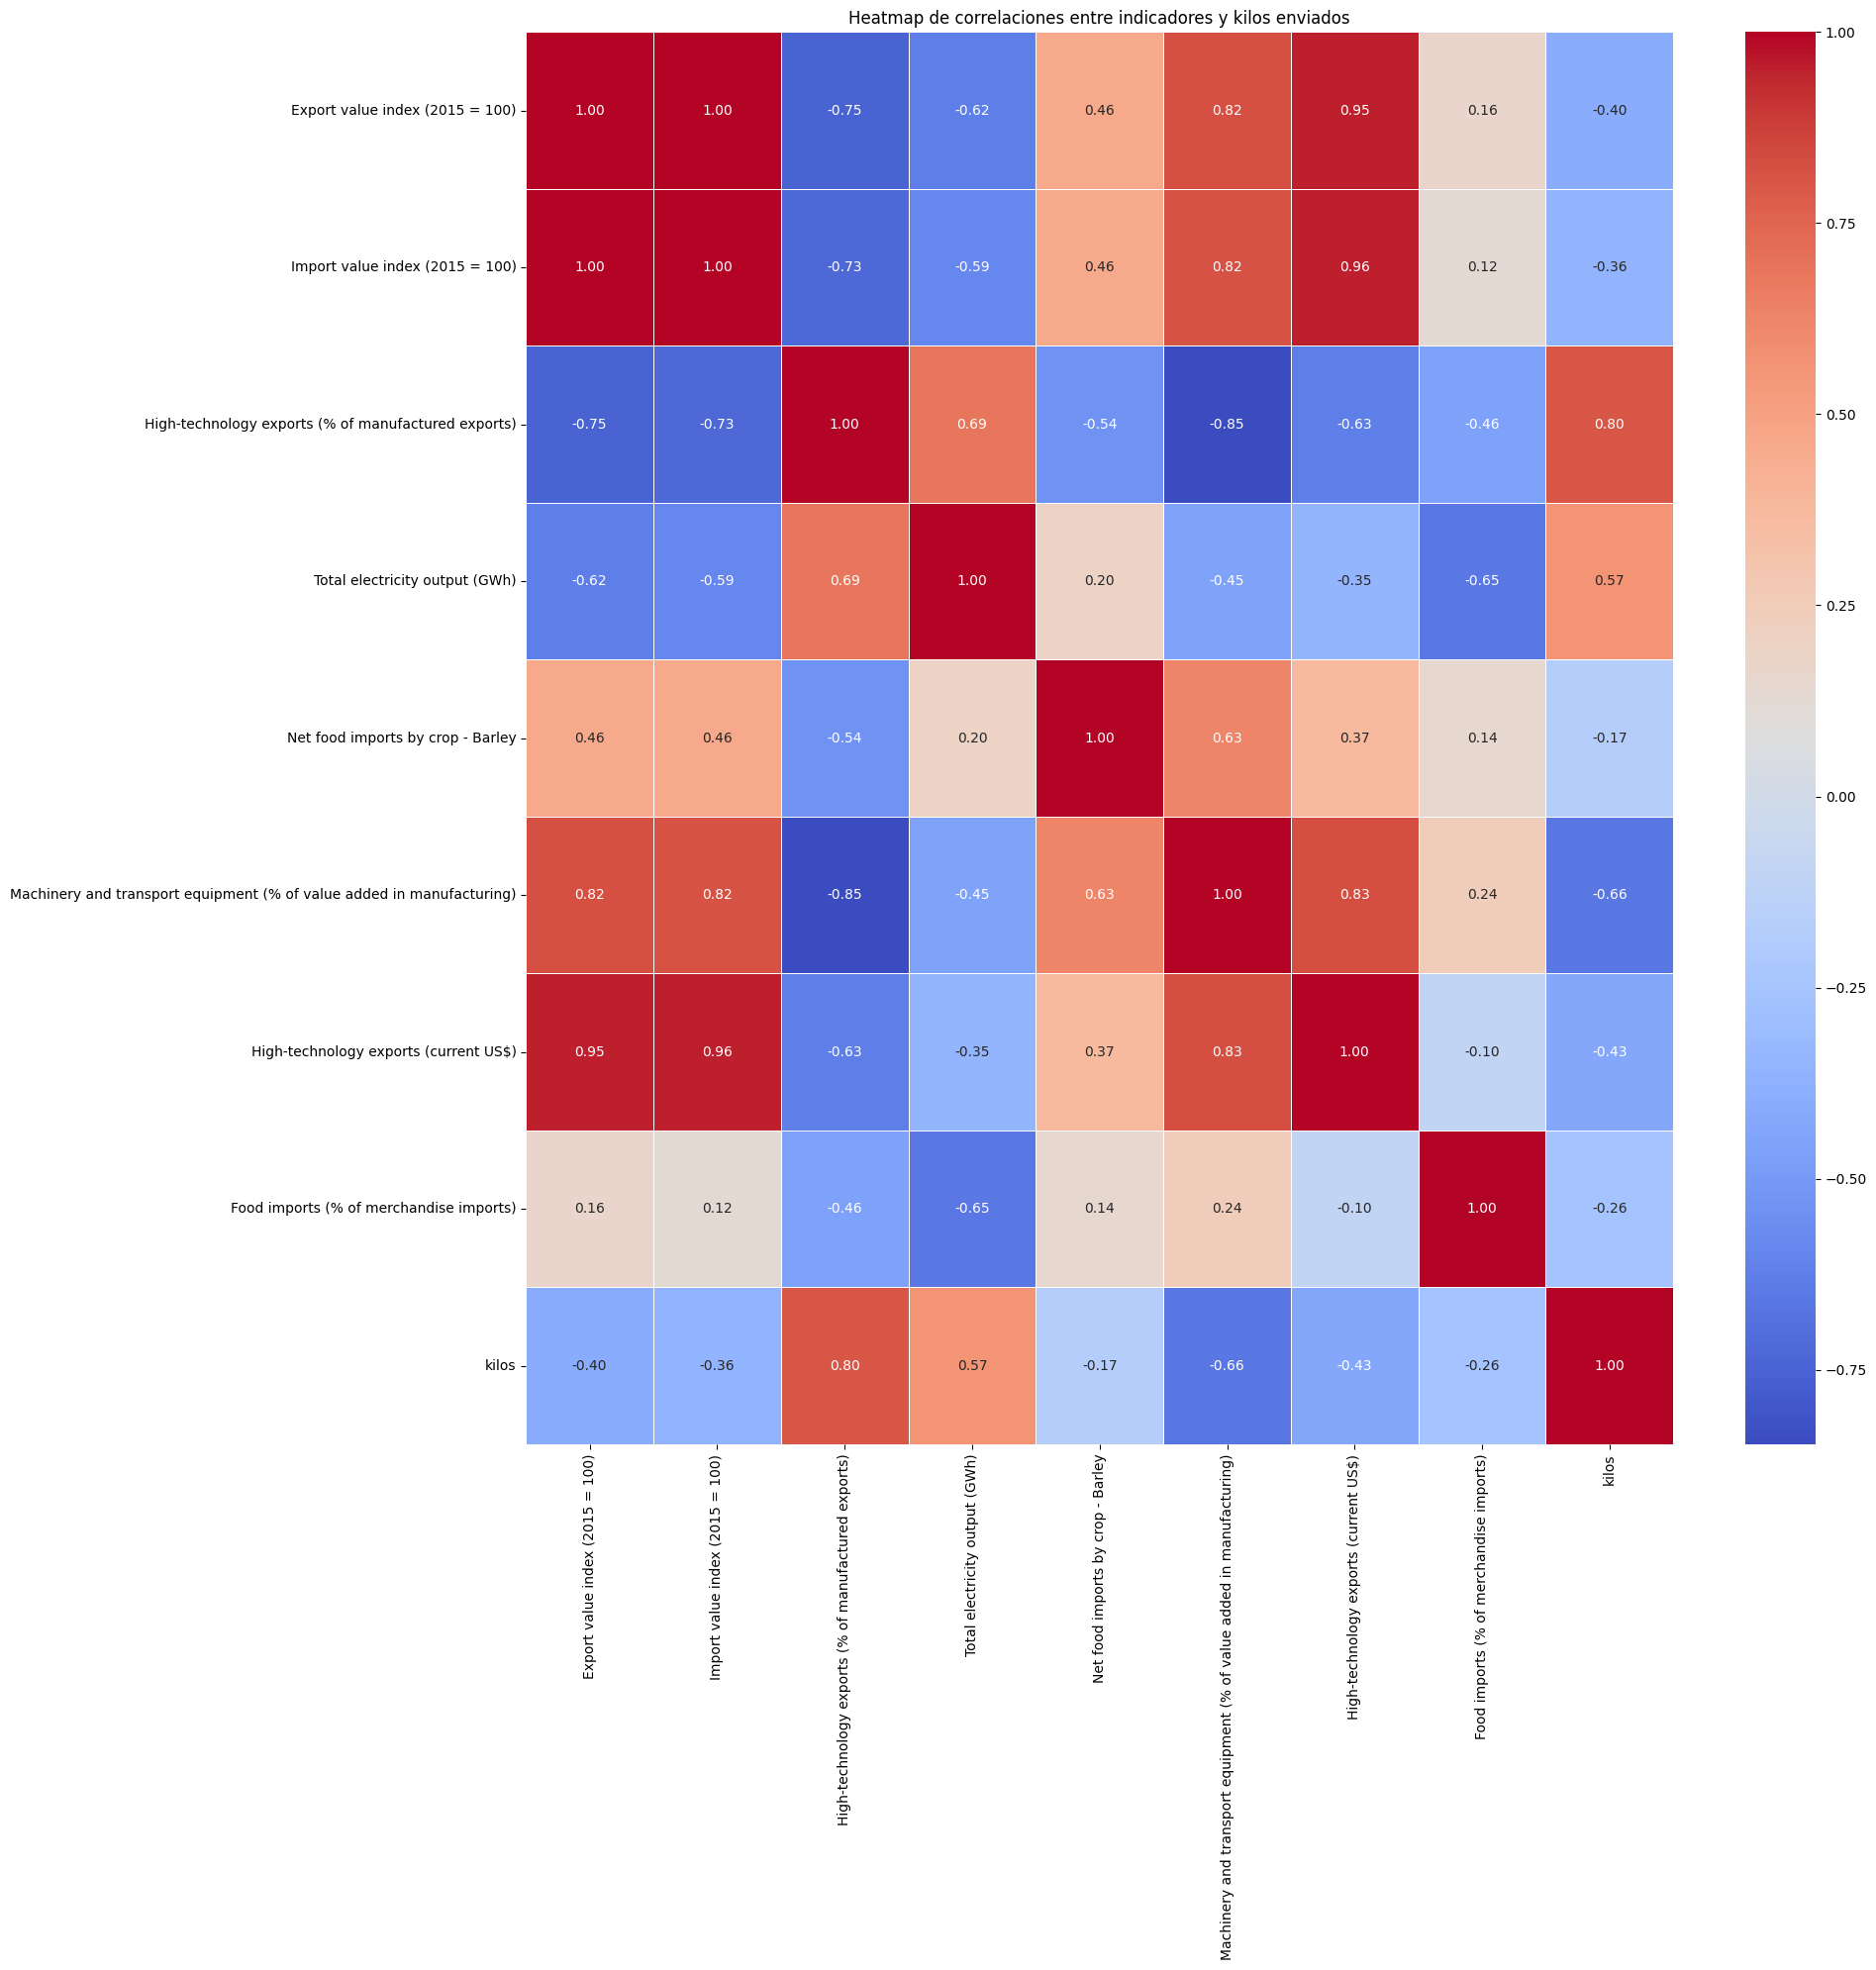

In [211]:
#Hacemos el heatmap
plt.figure(figsize=(20, 20))
sns.heatmap(
    corr_importaciones,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Heatmap de correlaciones entre indicadores y kilos enviados")
plt.tight_layout()
plt.show()